# Wine Quality Prediction

**Problem:** From 11 chemical measurements of a red wine (acidity, sugar, sulphates, alcohol…), predict whether it is a **good** wine (expert quality score ≥ 7) or not.

**Dataset:** UCI Wine Quality dataset — **1,599 red wines** with expert quality scores from 3 to 8.

**Approach:** Random Forest (with feature importance) vs Logistic Regression.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(URL, sep=";")
print("Wines:", df.shape)
df["good"] = (df["quality"] >= 7).astype(int)
print(df["good"].value_counts().rename({0: "not good", 1: "good"}))
X = df.drop(columns=["quality", "good"]); y = df["good"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

Wines: (1599, 12)
good
not good    1382
good         217
Name: count, dtype: int64


Logistic Regression accuracy: 0.8925
Random Forest accuracy: 0.94
              precision    recall  f1-score   support

    Not good      0.947     0.986     0.966       346
        Good      0.875     0.648     0.745        54

    accuracy                          0.940       400
   macro avg      0.911     0.817     0.855       400
weighted avg      0.937     0.940     0.936       400



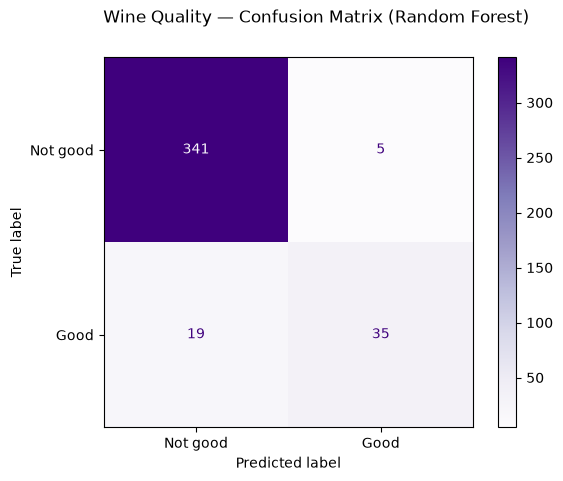

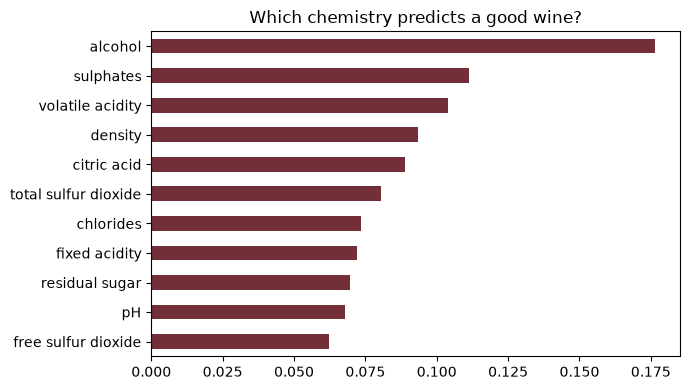

In [2]:
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_tr, y_tr)
sc = StandardScaler().fit(X_tr)
lr = LogisticRegression(max_iter=5000).fit(sc.transform(X_tr), y_tr)
for name, p in [("Logistic Regression", lr.predict(sc.transform(X_te))), ("Random Forest", rf.predict(X_te))]:
    print(name, "accuracy:", round(accuracy_score(y_te, p), 4))
print(classification_report(y_te, rf.predict(X_te), target_names=["Not good", "Good"], digits=3))
disp = ConfusionMatrixDisplay.from_predictions(y_te, rf.predict(X_te), display_labels=["Not good", "Good"], cmap="Purples")
disp.figure_.suptitle("Wine Quality — Confusion Matrix (Random Forest)")
disp.figure_.savefig("confusion_matrix.png", dpi=110, bbox_inches="tight")

plt.figure(figsize=(7, 4))
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot.barh(color="#722f37")
plt.title("Which chemistry predicts a good wine?")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=110, bbox_inches="tight")

## Result
**Random Forest: 94.0% accuracy; Logistic Regression: 89.3%** (executed output above). The feature-importance chart shows **alcohol** and **sulphates** carry most of the signal. Note the class imbalance — only about 14% of the wines are "good" — so the per-class report matters more than headline accuracy.